# Metodos de Segundo Orden

* Newton
* BFGS
* SR1 (Symmetric Rank 1)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
def double_well_potential(x, y):
    """Eq. (2.24): potencial de doble pozo con un punto casi degenerado."""
    return (15.0 * np.exp(-0.25 * (x + 2.0) ** 2)
            + 0.5 * np.exp(-2.0 * (x - 2.0) ** 2)
            + x ** 2 + y ** 2)

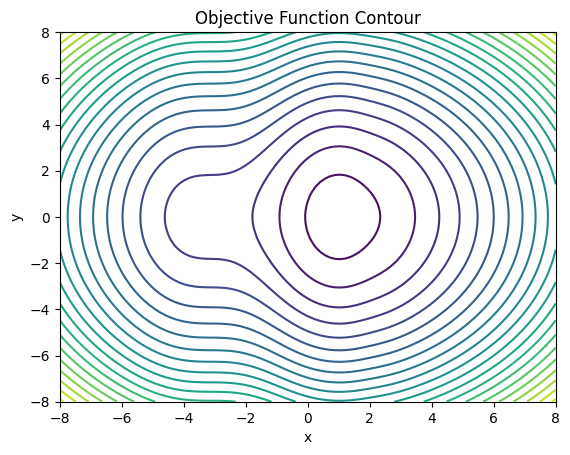

In [3]:
X, Y = np.meshgrid(np.linspace(-8, 8, 100), np.linspace(-8, 8, 100))
Z = 15.0 * np.exp(-0.25 * (X + 2.0) ** 2) + 0.5 * np.exp(-2.0 * (X - 2.0) ** 2) + X ** 2 + Y ** 2
# show the image
plt.contour(X, Y, Z, levels=20)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Objective Function Contour')
plt.show()

/tmp/ipykernel_6601/3203523034.py:53: RuntimeWarning: Method BFGS does not use Hessian information (hess).
  res_2 = minimize(obj_func, x0, jac=obj_grad, hess=obj_hess, method=method2, callback=callback_2)


=== OPTIMIZATION COMPARISON ===
Initial point: [-3.9  0. ]
Method       | Optimal x              | Function Value  | Iterations | Func Ev | Grad Ev | Success 
------------------------------------------------------------------------------------------------
Newton-CG    | [1.0180924 0.       ]  | 2.64774442      | 6          | 11      | 11      | True    
BFGS         | [1.01809241 0.        ] | 2.64774442      | 3          | 10      | 10      | True    


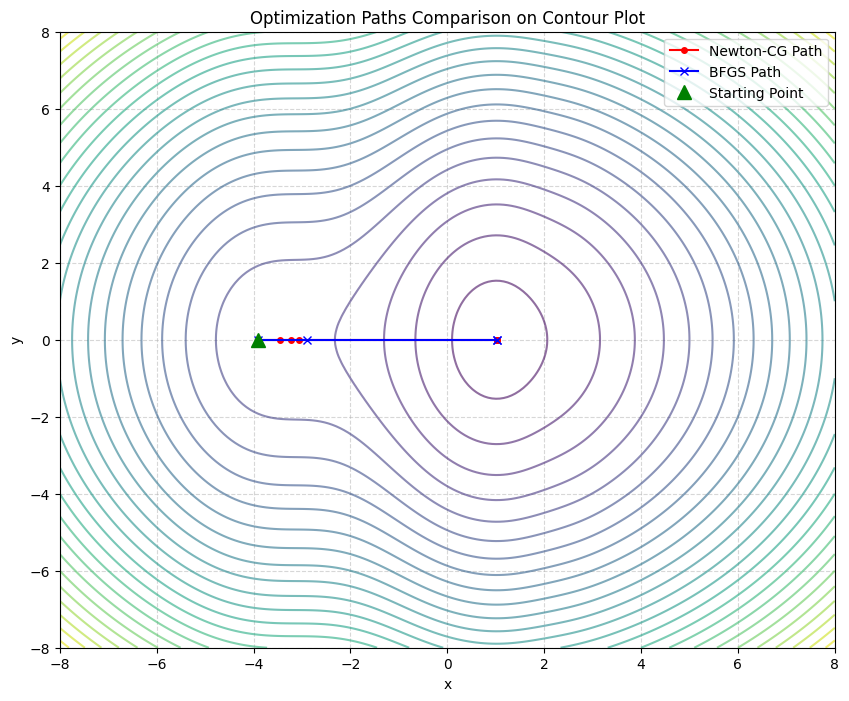

In [4]:
# solve this problem with the newton and the BFGS method and make a comparison

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# 1. Define objective function expecting a 1D vector of parameters [x, y]
def obj_func(v):
    x, y = v[0], v[1]
    return (15.0 * np.exp(-0.25 * (x + 2.0) ** 2)
            + 0.5 * np.exp(-2.0 * (x - 2.0) ** 2)
            + x ** 2 + y ** 2)

# 2. Define the analytical gradient (jacobian)
def obj_grad(v):
    x, y = v[0], v[1]
    df_dx = (15.0 * np.exp(-0.25 * (x + 2.0) ** 2) * (-0.5 * (x + 2.0))
             + 0.5 * np.exp(-2.0 * (x - 2.0) ** 2) * (-4.0 * (x - 2.0))
             + 2.0 * x)
    df_dy = 2.0 * y
    return np.array([df_dx, df_dy])

# 3. Define the analytical Hessian
def obj_hess(v):
    x, y = v[0], v[1]
    d2f_dx2 = (15.0 * np.exp(-0.25 * (x + 2.0) ** 2) * (-0.5 + 0.25 * (x + 2.0) ** 2)
               + 0.5 * np.exp(-2.0 * (x - 2.0) ** 2) * (-4.0 + 16.0 * (x - 2.0) ** 2)
               + 2.0)
    d2f_dxdy = 0.0
    d2f_dy2 = 2.0
    return np.array([[d2f_dx2, d2f_dxdy], [d2f_dxdy, d2f_dy2]])

# Starting point (placed slightly away to observe trajectory, e.g., near local/global boundary)
x0 = np.array([-3.9, 0.0])

# Track optimization path for visualization
path_1 = [x0]
path_2 = [x0]

# Nos da la opcion de ejecutar algo en medio de las iteraciones
def callback_1(xk):
    path_1.append(xk)

def callback_2(xk):
    path_2.append(xk)

# method1
method1 = 'Newton-CG'
res_1 = minimize(obj_func, x0, jac=obj_grad, method=method1, hess=obj_hess ,callback=callback_1)

# method2
method2 = 'BFGS'
res_2 = minimize(obj_func, x0, jac=obj_grad, hess=obj_hess, method=method2, callback=callback_2)

# Convert paths to numpy arrays for plotting
path_1 = np.array(path_1)
path_2 = np.array(path_2)

# 4. Print Comparison Table
print("=== OPTIMIZATION COMPARISON ===")
print(f"Initial point: {x0}")
print(f"{'Method':<12} | {'Optimal x':<22} | {'Function Value':<15} | {'Iterations':<10} | {'Func Ev':<7} | {'Grad Ev':<7} | {'Success':<8}")
print("-" * 96)
print(f"{method1:<12} | {str(res_1.x):<22} | {res_1.fun:<15.8f} | {res_1.nit:<10} | {res_1.nfev:<7} | {res_1.njev:<7} | {str(res_1.success):<8}")
print(f"{method2:<12} | {str(res_2.x):<22} | {res_2.fun:<15.8f} | {res_2.nit:<10} | {res_2.nfev:<7} | {res_2.njev:<7} | {str(res_2.success):<8}")

# 5. Plot comparison trajectories
X, Y = np.meshgrid(np.linspace(-8, 8, 200), np.linspace(-8, 8, 200))
Z = double_well_potential(X, Y)

plt.figure(figsize=(10, 8))
plt.contour(X, Y, Z, levels=30, cmap='viridis', alpha=0.6)
plt.plot(path_1[:, 0], path_1[:, 1], 'o-', color='red', label=f'{method1} Path', markersize=4)
plt.plot(path_2[:, 0], path_2[:, 1], 'x-', color='blue', label=f'{method2} Path', markersize=6)
plt.plot(x0[0], x0[1], 'g^', markersize=10, label='Starting Point')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Optimization Paths Comparison on Contour Plot')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [5]:
def newtons(f, grad_f, hess_f, x0, max_iter=100, tol=1e-6):
  '''
   ---------------------------------------------------------------------------
   Newton's Method - Raphson
   ---------------------------------------------------------------------------
   '''
  trajectory = [np.array(start)]
  values = [objective_function(*start)]
  point = np.array(start, dtype=float)

  for _ in range(max_iter):
      grad = grad_f(point[0], point[1])
      if np.linalg.norm(grad) < tol:
          break
      hess = hess_f(point[0], point[1])
      hess_inv = np.linalg.inv(hess)
      point -= hess_inv @ grad
      trajectory.append(point.copy())
      values.append(objective_function(point[0], point[1]))

  return np.array(trajectory), np.array(values)

def bfgs(f, grad_f, x0, max_iter=100, tol=1e-6):
    x = np.array(x0, dtype=float)
    I = np.eye(len(x))
    H = np.eye(len(x))  # Initial inverse Hessian approximation
    path = [x.copy()]

    for _ in range(max_iter):
        g = grad_f(x)
        if np.linalg.norm(g) < tol:
            break

        p = -H.dot(g)  # Search direction

        # Backtracking line search (Armijo condition)
        alpha = 1.0
        c1, rho = 1e-4, 0.9
        while f(x + alpha * p) > f(x) + c1 * alpha * g.dot(p):
            alpha *= rho
            if alpha < 1e-8:
                break

        s = alpha * p
        x_next = x + s
        y = grad_f(x_next) - g

        # Update inverse Hessian H
        rho_k = 1.0 / (y.dot(s) + 1e-10)
        H = (I - rho_k * np.outer(s, y)).dot(H).dot(I - rho_k * np.outer(y, s)) + rho_k * np.outer(s, s)

        x = x_next
        path.append(x.copy())

    return x, np.array(path)

def sr1(f, grad_f, x0, max_iter=100, tol=1e-6):
    x = np.array(x0, dtype=float)
    H = np.eye(len(x))  # Initial inverse Hessian approximation
    path = [x.copy()]

    for _ in range(max_iter):
        g = grad_f(x)
        if np.linalg.norm(g) < tol:
            break

        p = -H.dot(g)  # Search direction

        # Backtracking line search (Armijo condition)
        alpha = 1.0
        c1, rho = 1e-4, 0.9
        while f(x + alpha * p) > f(x) + c1 * alpha * g.dot(p):
            alpha *= rho
            if alpha < 1e-8:
                break

        s = alpha * p
        x_next = x + s
        y = grad_f(x_next) - g

        # Update inverse Hessian using SR1 update formula
        # H_{k+1} = H_k + ((s - H_k y)(s - H_k y)^T) / ((s - H_k y)^T y)
        diff = s - H.dot(y)
        denominator = diff.dot(y)

        # SR1 update is only applied if the denominator is sufficiently large to maintain stability
        if np.abs(denominator) > 1e-8 * np.linalg.norm(s) * np.linalg.norm(diff):
            H = H + np.outer(diff, diff) / denominator

        x = x_next
        path.append(x.copy())

    return x, np.array(path)

In [6]:
# Define the objective function and its derivatives   (Eq. 2.7)
def objective_function(x, y):
    return np.exp(x + 2 * y - 0.2) + np.exp(x - 2 * y - 0.2) + np.exp(-x - 0.2)


def gradient(x, y):
    grad_x = np.exp(x + 2 * y - 0.2) + np.exp(x - 2 * y - 0.2) - np.exp(-x - 0.2)
    grad_y = 2 * np.exp(x + 2 * y - 0.2) - 2 * np.exp(x - 2 * y - 0.2)
    return np.array([grad_x, grad_y])


def hessian(x, y):
    h_xx = np.exp(x + 2 * y - 0.2) + np.exp(x - 2 * y - 0.2) + np.exp(-x - 0.2)
    h_xy = 2 * np.exp(x + 2 * y - 0.2) - 2 * np.exp(x - 2 * y - 0.2)
    h_yy = 4 * np.exp(x + 2 * y - 0.2) + 4 * np.exp(x - 2 * y - 0.2)
    return np.array([[h_xx, h_xy], [h_xy, h_yy]])


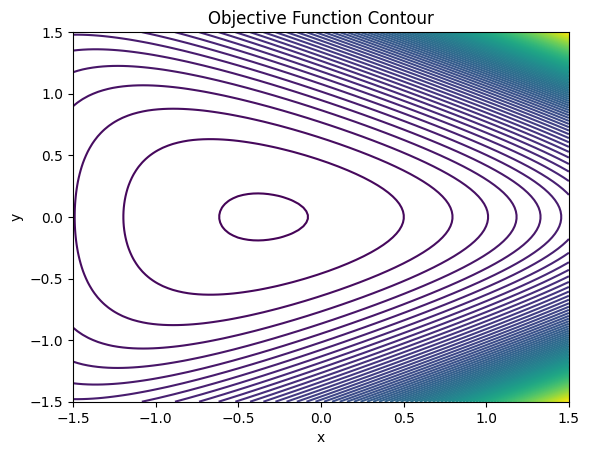

In [7]:
# create a contour graph using local variables to avoid overwriting global regression variables 'x' and 'y'
x_grid = np.linspace(-1.5, 1.5, 100)
y_grid = np.linspace(-1.5, 1.5, 100)
X, Y = np.meshgrid(x_grid, y_grid)
Z = objective_function(X, Y)
plt.contour(X, Y, Z, levels=100)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Objective Function Contour')
plt.show()



In [8]:
# Define helper wrappers to adapt objective_function, gradient, and hessian to vector inputs
def f_vec(v):
    return objective_function(v[0], v[1])

def grad_vec(v):
    return gradient(v[0], v[1])

def hess_vec(v):
    return hessian(v[0], v[1])

# Define starting point
start_point = np.array([1.0, 0.5])

# Run custom BFGS
final_bfgs, path_bfgs = bfgs(f_vec, grad_vec, start_point)

# Run custom SR1
final_sr1, path_sr1 = sr1(f_vec, grad_vec, start_point)

# Run custom Newton's Method (Newton-Raphson)
# Note: The custom newtons function uses global variables 'start', 'objective_function', 'grad_f', and 'hess_f'
# So we will define those globally temporarily to let it run properly
start = start_point
def grad_f(x, y): return gradient(x, y)
def hess_f(x, y): return hessian(x, y)

path_newton, values_newton = newtons(f_vec, grad_f, hess_f, start_point)
final_newton = path_newton[-1]

# Display paths
print("=== BFGS Trajectory ===")
for i, pt in enumerate(path_bfgs):
    print(f"Iter {i:2d}: position = {pt}, f(x,y) = {f_vec(pt):.8f}")

print("\n=== SR1 Trajectory ===")
for i, pt in enumerate(path_sr1):
    print(f"Iter {i:2d}: position = {pt}, f(x,y) = {f_vec(pt):.8f}")

print("\n=== Newton's Method Trajectory ===")
for i, pt in enumerate(path_newton):
    print(f"Iter {i:2d}: position = {pt}, f(x,y) = {f_vec(pt):.8f}")

# Print Comparison Table
print("\n=== COMPARISON SUMMARY ===")
print(f"{'Method':<12} | {'Optimal Coordinate (x, y)':<35} | {'Function Value':<15} | {'Iterations':<10}")
print("-" * 80)
print(f"{'Newton':<12} | {str(np.round(final_newton, 6)):<35} | {f_vec(final_newton):<15.8f} | {len(path_newton)-1:<10}")
print(f"{'BFGS':<12} | {str(np.round(final_bfgs, 6)):<35} | {f_vec(final_bfgs):<15.8f} | {len(path_bfgs)-1:<10}")
print(f"{'SR1':<12} | {str(np.round(final_sr1, 6)):<35} | {f_vec(final_sr1):<15.8f} | {len(path_sr1)-1:<10}")

=== BFGS Trajectory ===
Iter  0: position = [1.  0.5], f(x,y) = 7.16957243
Iter  1: position = [ 0.11287082 -0.91323856], f(x,y) = 6.57252139
Iter  2: position = [-1.92228288 -0.62962585], f(x,y) = 6.05316842
Iter  3: position = [-0.67296404 -0.38113533], f(x,y) = 2.69486350
Iter  4: position = [-0.44034087 -0.24457177], f(x,y) = 2.45456045
Iter  5: position = [-0.20485079 -0.04036854], f(x,y) = 2.34336593
Iter  6: position = [-0.27139364 -0.04785587], f(x,y) = 2.32798948
Iter  7: position = [-0.34233436 -0.01757655], f(x,y) = 2.31645960
Iter  8: position = [-0.3474886  -0.00266087], f(x,y) = 2.31573762
Iter  9: position = [-3.46669321e-01 -2.36847764e-05], f(x,y) = 2.31572028
Iter 10: position = [-3.46579418e-01  1.04602337e-06], f(x,y) = 2.31572027
Iter 11: position = [-3.46573640e-01  4.56854575e-08], f(x,y) = 2.31572027

=== SR1 Trajectory ===
Iter  0: position = [1.  0.5], f(x,y) = 7.16957243
Iter  1: position = [ 0.11287082 -0.91323856], f(x,y) = 6.57252139
Iter  2: position = [-

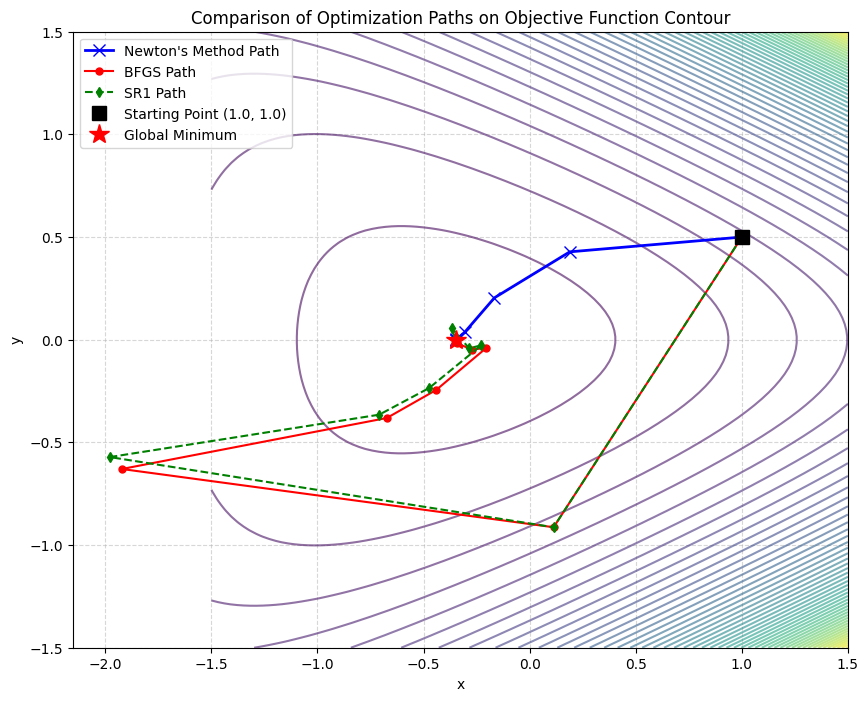

In [9]:
# Plot the paths of Newton, BFGS, and SR1 on top of the contour plot
x_grid = np.linspace(-1.5, 1.5, 100)
y_grid = np.linspace(-1.5, 1.5, 100)
X, Y = np.meshgrid(x_grid, y_grid)
Z = objective_function(X, Y)

plt.figure(figsize=(10, 8))
plt.contour(X, Y, Z, levels=50, cmap='viridis', alpha=0.6)

# Plot paths
plt.plot(path_newton[:, 0], path_newton[:, 1], 'x-', color='blue', label="Newton's Method Path", markersize=8, linewidth=2)
plt.plot(path_bfgs[:, 0], path_bfgs[:, 1], 'o-', color='red', label="BFGS Path", markersize=5, linewidth=1.5)
plt.plot(path_sr1[:, 0], path_sr1[:, 1], 'd--', color='green', label="SR1 Path", markersize=5, linewidth=1.5)

# Highlight starting and ending points
plt.plot(start_point[0], start_point[1], 'ks', markersize=10, label='Starting Point (1.0, 1.0)')
plt.plot(final_newton[0], final_newton[1], 'r*', markersize=15, label='Global Minimum')

plt.xlabel('x')
plt.ylabel('y')
plt.title("Comparison of Optimization Paths on Objective Function Contour")
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

=== OPTIMIZATION COMPARISON ===
Initial point: [1.2 1.3]
Method               | Optimal Coordinate (x, y)           | Function Value  | Iterations
----------------------------------------------------------------------------------------
Custom Newton        | [-0.346574  0.      ]               | 2.31572027      | 8         
SciPy Newton-CG      | [-0.346574 -0.      ]               | 2.31572027      | 9         


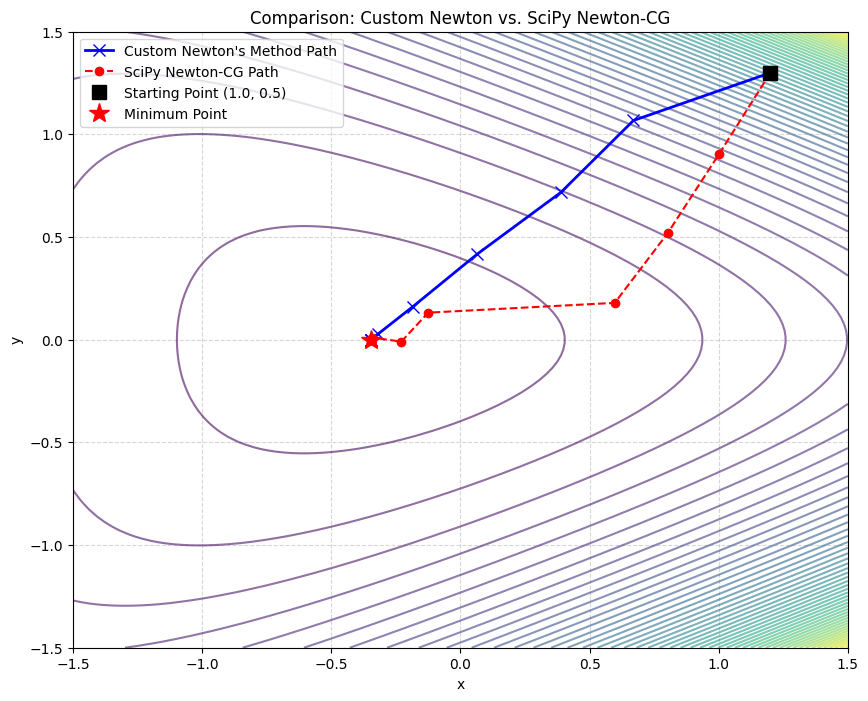

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# 1. Adapt functions to take 1D vector inputs for minimize()
def f_vec(v):
    return objective_function(v[0], v[1])

def grad_vec(v):
    return gradient(v[0], v[1])

def hess_vec(v):
    return hessian(v[0], v[1])

# Define starting point
start_point = np.array([1.2, 1.3])

# 2. Run custom Newton's Method
# Ensure global variables 'start' are set as expected by the custom newtons implementation
start = start_point
path_custom_newton, values_custom_newton = newtons(f_vec, grad_f, hess_f, start_point)
final_custom_newton = path_custom_newton[-1]

# 3. Run SciPy's Newton-CG
path_scipy_ncg = [start_point.copy()]
def callback_scipy(xk):
    path_scipy_ncg.append(xk.copy())

res_scipy = minimize(
    fun=f_vec,
    x0=start_point,
    jac=grad_vec,
    hess=hess_vec,
    method='Newton-CG',
    callback=callback_scipy
)
path_scipy_ncg = np.array(path_scipy_ncg)
final_scipy_ncg = res_scipy.x

# 4. Print Comparison Table
print("=== OPTIMIZATION COMPARISON ===")
print(f"Initial point: {start_point}")
print(f"{'Method':<20} | {'Optimal Coordinate (x, y)':<35} | {'Function Value':<15} | {'Iterations':<10}")
print("-" * 88)
print(f"{'Custom Newton':<20} | {str(np.round(final_custom_newton, 6)):<35} | {f_vec(final_custom_newton):<15.8f} | {len(path_custom_newton)-1:<10}")
print(f"{'SciPy Newton-CG':<20} | {str(np.round(final_scipy_ncg, 6)):<35} | {res_scipy.fun:<15.8f} | {res_scipy.nit:<10}")

# 5. Plot comparison trajectories on the contour plot
x_grid = np.linspace(-1.5, 1.5, 100)
y_grid = np.linspace(-1.5, 1.5, 100)
X_m, Y_m = np.meshgrid(x_grid, y_grid)
Z_m = objective_function(X_m, Y_m)

plt.figure(figsize=(10, 8))
plt.contour(X_m, Y_m, Z_m, levels=50, cmap='viridis', alpha=0.6)

# Plot paths
plt.plot(path_custom_newton[:, 0], path_custom_newton[:, 1], 'x-', color='blue', label="Custom Newton's Method Path", markersize=8, linewidth=2)
plt.plot(path_scipy_ncg[:, 0], path_scipy_ncg[:, 1], 'o--', color='red', label="SciPy Newton-CG Path", markersize=6, linewidth=1.5)

# Highlight starting and ending points
plt.plot(start_point[0], start_point[1], 'ks', markersize=10, label='Starting Point (1.0, 0.5)')
plt.plot(final_custom_newton[0], final_custom_newton[1], 'r*', markersize=15, label='Minimum Point')

plt.xlabel('x')
plt.ylabel('y')
plt.title("Comparison: Custom Newton vs. SciPy Newton-CG")
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()